# Credit Risk — Model Selection

This notebook only uses the development data (train + validation, 80%). **Test rows are never loaded.**

Order: feature sets → `organization_type` → `code_gender` → hyperparameter search → SHAP → calibration → threshold → fairness.

Decisions follow fixed rules: when a difference is smaller than one average fold std, the simpler option stays. Results are written to `artifacts/final_config.json`, which the final test reads.

In [1]:
import json, math, random, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb, shap
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from modeling_utils import *

engine = get_engine()
dev = load_split(engine, ["train", "val"])
assert set(dev["split"]) == {"train", "val"}
base, ratio, window = feature_groups(dev.columns)
categories = {c: sorted(dev[c].dropna().unique()) for c in base if not pd.api.types.is_numeric_dtype(dev[c])}
y = dev[TARGET].to_numpy()
credit = dev["amt_credit"].to_numpy()
print(f"{len(dev):,} rows | base {len(base)} | ratios {len(ratio)} | windows {len(window)} | categorical {len(categories)}")

246,008 rows | base 156 | ratios 13 | windows 64 | categorical 16


## 1. Feature sets (5-fold CV)

Early stopping runs on the same fold, so CV scores are slightly optimistic; they are fine for comparison, and the unbiased result comes from the final test.

In [2]:
t0 = time.time()
sets = {"base": base, "base + ratios": base + ratio, "base + windows": base + window, "all": base + ratio + window}
cv_sets = {k: run_cv(dev, v, categories) for k, v in sets.items()}
tab = pd.DataFrame({k: {"features": len(sets[k]), **cv_row(v)} for k, v in cv_sets.items()}).T
print(f"{time.time()-t0:.0f} s"); tab.round(5)

156 s


,features,CV AUC,std,train AUC,train-CV gap,trees
base,156.0,0.77216,0.00164,0.85725,0.08508,390.0
base + ratios,169.0,0.77640,0.00173,0.85845,0.08206,334.0
base + windows,220.0,0.78131,0.00148,0.86374,0.08243,343.0
all,233.0,0.78446,0.00110,0.87945,0.09500,438.0


In [3]:
se = float(np.mean([v["auc_std"] for v in cv_sets.values()]))
order = ["base", "base + ratios", "base + windows", "all"]
best_set = max(order, key=lambda k: cv_sets[k]["auc"])
features = sets[best_set]
print("selected set:", best_set, "| average fold std:", round(se, 5))

selected set: all | average fold std: 0.00149


## 2. `organization_type`

Four options: default categorical handling, strict regularization, in-fold target encoding, dropping the column. If it overfits, the train-CV gap narrows while CV AUC does not drop.

In [4]:
ORG = "organization_type"
strict = dict(cat_smooth=100, min_data_per_group=500, cat_l2=50, max_cat_threshold=16)
org = {
    "default": cv_sets[best_set],
    "strict categorical": run_cv(dev, features, categories, strict),
    "target encoding": run_cv(dev, features, categories, encode_column=ORG),
    "dropped": run_cv(dev, [c for c in features if c != ORG], categories),
}
pd.DataFrame({k: cv_row(v) for k, v in org.items()}).T.round(5)

,CV AUC,std,train AUC,train-CV gap,trees
default,0.78446,0.00110,0.87945,0.09500,438.0
strict categorical,0.78541,0.00127,0.87319,0.08779,372.0
target encoding,0.78572,0.00128,0.88097,0.09526,486.0
dropped,0.78509,0.00096,0.88432,0.09923,462.0


In [5]:
ref = org["default"]["auc"]
gains = {k: v["auc"] - ref for k, v in org.items()}
org_choice = max(gains, key=gains.get)
if gains[org_choice] < org["default"]["auc_std"]:
    # no meaningful CV gain: pick the option with the same score and less overfitting
    near = [k for k in ("strict categorical", "default") if org[k]["auc"] >= ref - org["default"]["auc_std"] / 2]
    org_choice = near[0]
extra_params = strict if org_choice == "strict categorical" else {}
encode_column = ORG if org_choice == "target encoding" else None
if org_choice == "dropped":
    features = [c for c in features if c != ORG]
print("organization_type decision:", org_choice)

organization_type decision: target encoding


## 3. Should `code_gender` stay in the model?

Using gender directly in credit decisions is problematic under many regulations. Rule: drop the column if the AUC loss is below 0.002.

In [6]:
GENDER = "code_gender"
with_g = run_cv(dev, features, categories, extra_params, encode_column=encode_column)
without_g = run_cv(dev, [c for c in features if c != GENDER], categories, extra_params, encode_column=encode_column)
gender_loss = with_g["auc"] - without_g["auc"]
print(pd.DataFrame({"with": cv_row(with_g), "without": cv_row(without_g)}).T.round(5))
if gender_loss < 0.002:
    features = [c for c in features if c != GENDER]
print(f"AUC loss {gender_loss:.5f} -> code_gender", "dropped" if GENDER not in features else "kept")

          CV AUC      std  train AUC  train-CV gap  trees
with     0.78572  0.00128    0.88097       0.09526  486.0
without  0.78377  0.00194    0.87736       0.09359  443.0
AUC loss 0.00195 -> code_gender dropped


## 4. Hyperparameter search

Random search with 30 trials, 3-fold. The best candidate is compared with the defaults again on a 5-fold CV with a different seed, because the search score is optimistic due to selection.

In [7]:
rng = random.Random(SEED)
def sample():
    return dict(
        num_leaves=rng.choice([15, 23, 31, 47, 63, 95]),
        min_child_samples=rng.choice([50, 100, 200, 400, 800]),
        colsample_bytree=rng.uniform(0.15, 0.9),
        subsample=rng.uniform(0.6, 1.0),
        reg_lambda=10 ** rng.uniform(-1, 2.5),
        reg_alpha=10 ** rng.uniform(-2, 1),
        min_split_gain=rng.choice([0.0, 0.1, 0.5, 1.0]),
    )
t0, trials = time.time(), []
for i in range(30):
    p = sample()
    r = run_cv(dev, features, categories, {**extra_params, **p}, n_splits=3, encode_column=encode_column)
    trials.append({**p, "auc": r["auc"], "train_auc": r["train_auc"], "iter": r["best_iter"]})
    print(i, round(r["auc"], 5), f"{time.time()-t0:.0f}s", flush=True)
trials = pd.DataFrame(trials).sort_values("auc", ascending=False)
trials.head(5).round(4)

0 0.77877 44s


1 0.78047 80s


2 0.78175 122s


3 0.78294 200s


4 0.78151 240s


5 0.78212 277s


... (21 outputs left out)

27 0.78256 1246s


28 0.78144 1274s


29 0.78319 1328s


,num_leaves,min_child_samples,colsample_bytree,subsample,reg_lambda,reg_alpha,min_split_gain,auc,train_auc,iter
18,23,200,0.7219,0.8158,53.1120,0.3900,0.0,0.7847,0.8568,538
16,15,200,0.4761,0.7815,217.9494,4.2419,0.5,0.7846,0.8393,1076
9,23,400,0.4346,0.9958,17.3780,0.4687,0.5,0.7844,0.8660,702
22,23,800,0.7164,0.8759,31.2839,0.1574,0.5,0.7843,0.8614,564
11,23,400,0.4467,0.9658,4.0363,0.0623,0.1,0.7842,0.8748,627


In [8]:
best = trials.iloc[0].drop(["auc", "train_auc", "iter"]).to_dict()
for k in ("num_leaves", "min_child_samples"):
    best[k] = int(best[k])
CHECK_SEED = 7
default_cv = run_cv(dev, features, categories, extra_params, seed=CHECK_SEED, encode_column=encode_column)
tuned_cv = run_cv(dev, features, categories, {**extra_params, **best}, seed=CHECK_SEED, encode_column=encode_column)
print(pd.DataFrame({"default": cv_row(default_cv), "tuned": cv_row(tuned_cv)}).T.round(5))
use_tuned = tuned_cv["auc"] > default_cv["auc"]
final_params = {**extra_params, **(best if use_tuned else {})}
final_cv = tuned_cv if use_tuned else default_cv
# the final model is trained on all dev data, so the tree count is scaled for 25% more data
n_trees = int(final_cv["best_iter"] * 1.25)
oof = final_cv["oof"]
print("using tuned parameters:", use_tuned, "| trees:", n_trees)
pd.Series(score_metrics(y, oof)).round(4)

          CV AUC      std  train AUC  train-CV gap  trees
default  0.78488  0.00276    0.88922       0.10434  542.0
tuned    0.78728  0.00227    0.85450       0.06722  659.0
using tuned parameters: True | trees: 823


ROC-AUC    0.7872
Gini       0.5745
PR-AUC     0.2769
LogLoss    0.2373
Brier      0.0660
dtype: float64

## 5. SHAP

The model is trained on 4 folds and explained on a 5,000-row sample from the remaining fold.

In [9]:
X = to_lgb_frame(dev, features, categories)
tr, va = next(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))
X_tr, X_va = X.iloc[tr], X.iloc[va]
if encode_column:
    X_tr, X_va = encode_fold(X_tr, y[tr], X_va, encode_column)
params = {**LGB_PARAMS, **final_params, "n_estimators": final_cv["best_iter"]}
shap_model = lgb.LGBMClassifier(**params).fit(X_tr, y[tr])
sample_X = X_va.sample(5000, random_state=SEED)
sv = shap.TreeExplainer(shap_model).shap_values(sample_X)
sv = sv[1] if isinstance(sv, list) else sv
sv = sv[..., 1] if sv.ndim == 3 else sv
imp = pd.Series(np.abs(sv).mean(0), index=features).sort_values(ascending=False)
share = imp / imp.sum()
def source(c):
    if c in ratio: return "ratios"
    if c in window: return "windows"
    if c.startswith("bureau_"): return "bureau"
    if c.startswith("prev_"): return "previous_application"
    return "application"
print(share.groupby(source).sum().sort_values(ascending=False).map("{:.1%}".format))
print("organization_type SHAP share:", f"{share.get(ORG, 0):.2%}", "| rank:", (list(imp.index).index(ORG) + 1) if ORG in imp else None)
share.head(20).map("{:.2%}".format)

application             39.5%
windows                 23.7%
ratios                  23.1%
previous_application     8.6%
bureau                   5.1%
dtype: str
organization_type SHAP share: 1.79% | rank: 15


/Users/denizsahiner/credit-risk-model/venv/lib/python3.14/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


fe_ext_source_mean                      8.84%
fe_credit_annuity_ratio                 2.84%
fe_goods_credit_ratio                   2.59%
amt_annuity                             2.32%
prev_avg_credit_to_application_ratio    2.21%
fe_ext_source_max                       2.13%
occupation_type                         2.08%
name_education_type                     2.06%
fe_inst_avg_days_late_24m               1.96%
days_birth                              1.92%
days_employed                           1.86%
ext_source_3                            1.86%
own_car_age                             1.85%
name_family_status                      1.83%
organization_type                       1.79%
fe_ext_source_min                       1.74%
fe_inst_count_24m                       1.64%
bureau_max_overdue_amount               1.54%
fe_annuity_income_ratio                 1.53%
fe_bureau_active_debt_credit_ratio      1.49%
dtype: str

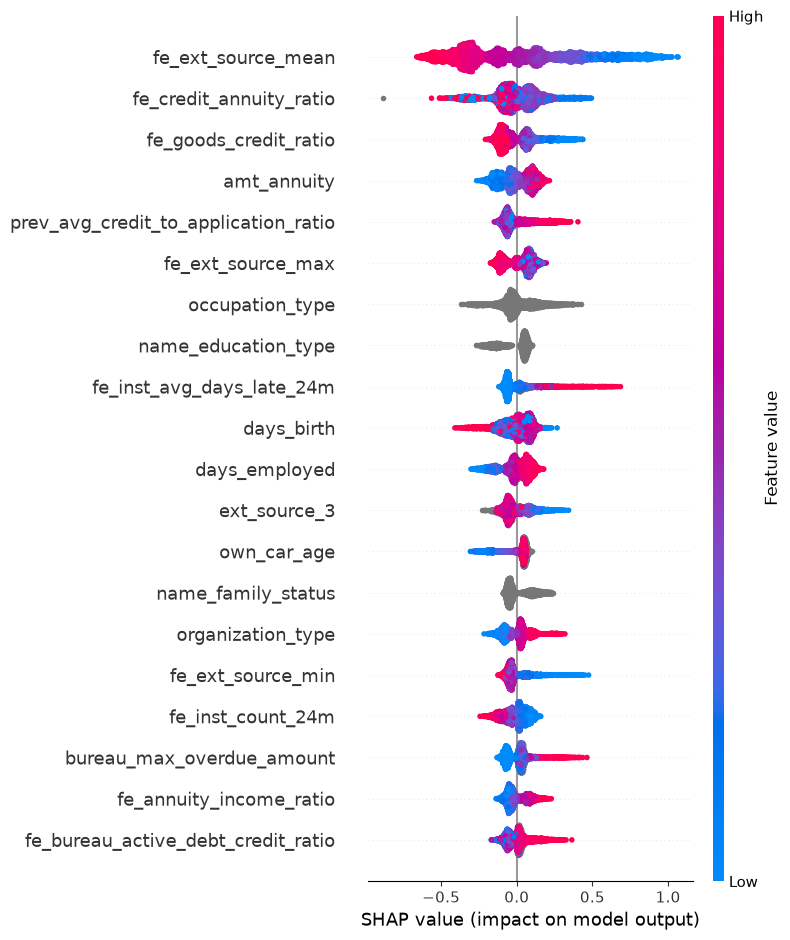

In [10]:
shap.summary_plot(sv, sample_X, max_display=20, show=False)
plt.tight_layout(); plt.savefig(ARTIFACTS / "shap_summary.png", dpi=130); plt.show()

## 6. Calibration

Calibrators are cross-validated on the OOF predictions. If Brier and LogLoss do not improve together, the raw probabilities stay.

In [11]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)
def crossfit(kind):
    out = np.zeros(len(y))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(oof, y):
        if kind == "platt":
            out[b] = LogisticRegression(C=1e6).fit(logit(oof[a]), y[a]).predict_proba(logit(oof[b]))[:, 1]
        else:
            out[b] = IsotonicRegression(out_of_bounds="clip").fit(oof[a], y[a]).predict(oof[b])
    return out
cal = {"raw": oof, "platt": crossfit("platt"), "isotonic": crossfit("isotonic")}
cal_tab = pd.DataFrame({k: {**score_metrics(y, v), "ECE": expected_calibration_error(y, v), "mean PD": v.mean()} for k, v in cal.items()}).T
print("observed rate:", round(y.mean(), 5)); cal_tab.round(5)

observed rate: 0.08073


,ROC-AUC,Gini,PR-AUC,LogLoss,Brier,ECE,mean PD
raw,0.78724,0.57448,0.27694,0.23726,0.06603,0.00328,0.08008
platt,0.78723,0.57447,0.27692,0.23725,0.06602,0.00297,0.08073
isotonic,0.78660,0.57320,0.27421,0.23760,0.06601,0.00061,0.08075


calibration decision: raw


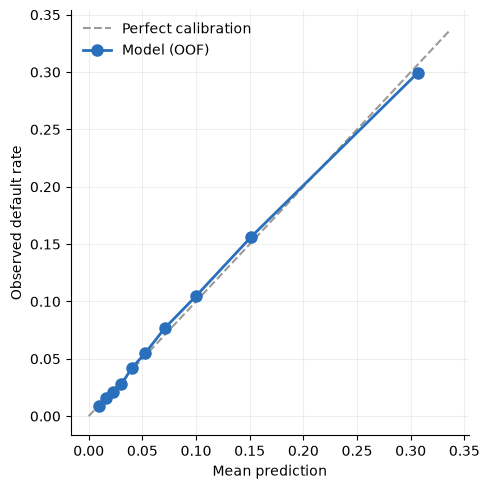

,mean_predicted,observed_rate,n
0,0.0096,0.0087,24601
1,0.0163,0.0156,24601
2,0.0228,0.0212,24601
3,0.0304,0.0276,24600
4,0.0399,0.0416,24601
5,0.0527,0.0550,24601
6,0.0710,0.0769,24600
7,0.0997,0.1045,24601
8,0.1516,0.1566,24601
9,0.3067,0.2995,24601


In [12]:
cal_choice = "raw"
for k in ("platt", "isotonic"):
    if cal_tab.loc[k, "Brier"] < cal_tab.loc[cal_choice, "Brier"] - 1e-5 and cal_tab.loc[k, "LogLoss"] < cal_tab.loc[cal_choice, "LogLoss"]:
        cal_choice = k
pd_oof = cal[cal_choice]
print("calibration decision:", cal_choice)
rel = reliability_table(y, pd_oof)
fig, ax = plt.subplots(figsize=(5, 5))
lim = max(rel.max(numeric_only=True)[["mean_predicted", "observed_rate"]]) * 1.1
ax.plot([0, lim], [0, lim], color="#9a9a9a", lw=1.5, ls="--", label="Perfect calibration")
ax.plot(rel["mean_predicted"], rel["observed_rate"], color="#2a6fbb", lw=2, marker="o", ms=8, label="Model (OOF)")
ax.set_xlabel("Mean prediction"); ax.set_ylabel("Observed default rate"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(ARTIFACTS / "calibration_oof.png", dpi=130); plt.show()
rel.round(4)

## 7. Threshold and business metric

The data has no interest or recovery information. **Assumption:** a good loan earns 15% of its amount and a default loses 50% (`MARGIN`, `LGD`). The data only contains loans that were approved in the past, so approval rates refer to that population, not to the real application flow.

In [13]:
grid = np.round(np.arange(0.02, 0.5001, 0.005), 3)
policy = pd.DataFrame([policy_row(y, pd_oof, credit, t) for t in grid])
threshold = float(policy.loc[policy["profit / total credit"].idxmax(), "threshold"])
print("profit-maximizing threshold:", threshold)
targets = [np.quantile(pd_oof, q) for q in (.6, .7, .8, .9, .95)]
pd.DataFrame([policy_row(y, pd_oof, credit, t) for t in targets + [threshold, 1.01]]).round(4)

profit-maximizing threshold: 0.22


,threshold,approval rate,default rate (approved),defaults rejected,profit / total credit
0,0.0605,0.6000,0.0283,0.7897,0.0826
1,0.0831,0.7000,0.0352,0.6945,0.0925
2,0.1197,0.8000,0.0439,0.5651,0.1003
3,0.1934,0.9000,0.0564,0.3710,0.1049
4,0.2748,0.9500,0.0655,0.2292,0.1049
5,0.2200,0.9203,0.0595,0.3219,0.1053
6,1.0100,1.0000,0.0807,0.0000,0.1012


In [14]:
sens = {}
for m in (.10, .15, .20, .30):
    sens[f"margin {m:.0%}"] = {f"LGD {l:.0%}": policy_row(y, pd_oof, credit, grid[np.argmax([policy_row(y, pd_oof, credit, t, m, l)["profit / total credit"] for t in grid])], m, l)["approval rate"] for l in (.3, .5, .7)}
print("Approval rate at the profit-maximizing threshold, by assumption:")
pd.DataFrame(sens).round(3)

Approval rate at the profit-maximizing threshold, by assumption:


,margin 10%,margin 15%,margin 20%,margin 30%
LGD 30%,0.941,0.970,0.984,0.994
LGD 50%,0.871,0.920,0.945,0.976
LGD 70%,0.790,0.871,0.920,0.970


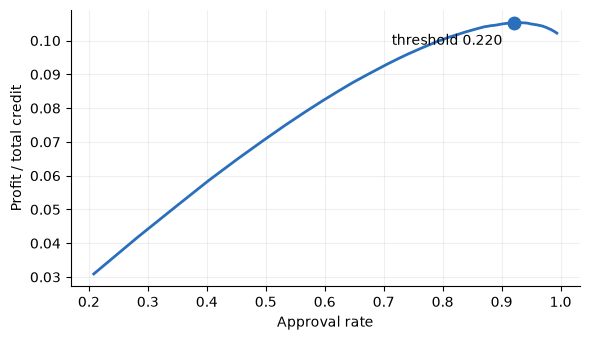

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(policy["approval rate"], policy["profit / total credit"], color="#2a6fbb", lw=2)
sel = policy.loc[policy["threshold"] == threshold].iloc[0]
ax.plot(sel["approval rate"], sel["profit / total credit"], "o", color="#2a6fbb", ms=9)
ax.annotate(f"threshold {threshold:.3f}", (sel["approval rate"], sel["profit / total credit"]), textcoords="offset points", xytext=(-8, -16), ha="right")
ax.set_xlabel("Approval rate"); ax.set_ylabel("Profit / total credit"); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(ARTIFACTS / "profit_curve_oof.png", dpi=130); plt.show()

## 8. Fairness

Even with `code_gender` removed, proxy variables can remain, so results are measured per group.

In [16]:
gender = dev["code_gender"].to_numpy(dtype=object)
ft = fairness_table(y, pd_oof, gender, threshold)
print("Approval rate F/M:", round(ft.loc["F", "approval rate"] / ft.loc["M", "approval rate"], 3),
      "| good-customer approval F/M:", round(ft.loc["F", "approval rate (good)"] / ft.loc["M", "approval rate (good)"], 3))
ft.round(4)

Approval rate F/M: 1.047 | good-customer approval F/M: 1.033


,n,actual default rate,mean PD,AUC,approval rate,approval rate (good),approval rate (bad),default rate (approved)
F,161887.0,0.0700,0.0728,0.7873,0.9346,0.9518,0.7057,0.0529
M,84119.0,0.1014,0.0940,0.7780,0.8928,0.9211,0.6416,0.0728


In [17]:
fairness_table(y, pd_oof, age_band(dev["days_birth"]), threshold).round(4)

,n,actual default rate,mean PD,AUC,approval rate,approval rate (good),approval rate (bad),default rate (approved)
30-44,98993.0,0.0904,0.0887,0.7908,0.9024,0.9281,0.6444,0.0646
45-59,82624.0,0.0649,0.0654,0.7811,0.9501,0.9640,0.7500,0.0512
60+,28110.0,0.0491,0.0480,0.7445,0.9810,0.9857,0.8883,0.0444
<30,36281.0,0.1148,0.1148,0.7629,0.8540,0.8884,0.5887,0.0791


## 9. Save the decisions

In [18]:
ARTIFACTS.mkdir(exist_ok=True)
config = dict(
    features=features, categories={k: [str(x) for x in v] for k, v in categories.items()},
    params=final_params, n_trees=n_trees, encode_column=encode_column,
    calibration=cal_choice, threshold=threshold,
    feature_set=best_set, organization_type=org_choice,
    code_gender_removed=GENDER not in features, cv_auc=final_cv["auc"], cv_auc_std=final_cv["auc_std"],
    oof_metrics=score_metrics(y, pd_oof), oof_policy=policy_row(y, pd_oof, credit, threshold),
)
json.dump(config, open(ARTIFACTS / "final_config.json", "w"), ensure_ascii=False, indent=1, default=float)
pd.DataFrame({ID: dev[ID], "oof": oof}).to_csv(ARTIFACTS / "oof.csv", index=False)
{k: config[k] for k in ("feature_set", "organization_type", "code_gender_removed", "n_trees", "calibration", "threshold", "cv_auc")}

{'feature_set': 'all',
 'organization_type': 'target encoding',
 'code_gender_removed': True,
 'n_trees': 823,
 'calibration': 'raw',
 'threshold': 0.22,
 'cv_auc': 0.7872804502790904}